# GMM Clean Source Sanity Check

This notebook checks the first clean end-to-end path:

1. Build a small GMM config.
2. Load train and reference tensors.
3. Plot the known intrinsic space.
4. Build the GDFM model with an MLP.
5. Run a short training loop.
6. Sample with Heun.
7. Compute nearest-neighbor and GMM metrics.

This run does not target model quality. It verifies the clean path from configuration to metrics.

## 1. Import the clean source

Locate the clean repository root. Add it to `sys.path`. Import only the required modules.

In [1]:
# Purpose: Import dependencies and set the deterministic notebook environment.
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch

# Find the repository root from the current working directory.
cwd = Path.cwd().resolve()
for candidate in (cwd, *cwd.parents):
    if (candidate / "mem_param_src").is_dir():
        REPO_ROOT = candidate
        break
else:
    # Use this path when the current directory is outside the repository.
    REPO_ROOT = Path(
        "/Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean"
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mem_param_src import GDFM, get_base_config
from mem_param_src.datasets import build_data_bundle
from mem_param_src.metrics import compute_memorization_metrics, compute_nn_stats
from mem_param_src.metrics.synthetic import gmm_intrinsic_metrics, project_to_subspace

plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["axes.grid"] = True

torch.manual_seed(7)
print(f"repo root: {REPO_ROOT}")
print(f"torch: {torch.__version__}")

repo root: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean
torch: 2.9.1


## 2. Build a small GMM config

We use a small ambient dimension and a two-dimensional intrinsic subspace. This makes plots easy to read.

In [2]:
# Purpose: Define the complete GMM sanity configuration.
cfg = get_base_config()

# Define the study identity.
cfg.study.name = "gmm_clean_smoke"
cfg.study.dataset_key = "gmm_subspace"
cfg.outputs.run_name = "gmm_clean_smoke"

# Use the same x-space target for prediction and loss.
cfg.framework.family = "fm"
cfg.framework.prediction_space = "x"
cfg.framework.loss_space = "x"
cfg.framework.loss_weighting = "unit"

# Define the small synthetic dataset.
cfg.data.dataset = "gmm_subspace"
cfg.data.root = "synthetic"
cfg.data.n_train = 5
cfg.data.n_test = 256
cfg.data.data_dim = 2
cfg.data.ambient_dim = 2
cfg.data.intrinsic_dim = 2
cfg.data.n_clusters = 3
cfg.data.sigma_z = 0.805
cfg.data.sigma_eta = 1.0e-4
cfg.data.geometry_seed = 24

# Define the small MLP.
cfg.network.arch = "mlp"
cfg.network.hidden_dim = 128
cfg.network.n_layers = 3
cfg.network.time_emb_dim = 64

# Define the short CPU training schedule.
cfg.training.seed = 7
cfg.training.batch_cap = 64
cfg.training.batch_size = 64
cfg.training.lr = 1.0e-3
cfg.training.weight_decay = 0.0
cfg.training.n_training_steps = 10000
cfg.training.start_time = 0.01
cfg.training.end_time = 0.99
cfg.training.use_safe_div = True
cfg.training.safe_div_denominator_floor = 0.01

# Define the sampler and evaluation settings.
cfg.sampling.method = "heun"
cfg.sampling.n_steps = 50
cfg.sampling.start_time = 0.01
cfg.sampling.end_time = 0.99
cfg.sampling.use_safe_div = True
cfg.sampling.safe_div_denominator_floor = 0.01
cfg.sampling.output = "x_t_max"
cfg.evaluation.n_samples = 128
cfg.evaluation.sample_bank_size = 128
cfg.evaluation.f_mem_threshold = 0.3
cfg.evaluation.chunk_size = 256

for key, value in {
    "dataset": cfg.data.dataset,
    "train/reference": f"{cfg.data.n_train}/{cfg.data.n_test}",
    "ambient_dim": cfg.data.data_dim,
    "intrinsic_dim": cfg.data.intrinsic_dim,
    "clusters": cfg.data.n_clusters,
    "prediction/loss": f"{cfg.framework.prediction_space}/{cfg.framework.loss_space}",
    "training_steps": cfg.training.n_training_steps,
    "training_time": f"{cfg.training.start_time} -> {cfg.training.end_time}",
    "training_use_safe_div": cfg.training.use_safe_div,
    "sampler": f"{cfg.sampling.method}, {cfg.sampling.n_steps} steps",
    "sampling_time": f"{cfg.sampling.start_time} -> {cfg.sampling.end_time}",
    "sampling_safe_div": cfg.sampling.use_safe_div,
    "sampling_output": cfg.sampling.output,
}.items():
    print(f"{key:16s}: {value}")

dataset         : gmm_subspace
train/reference : 5/256
ambient_dim     : 2
intrinsic_dim   : 2
clusters        : 3
prediction/loss : x/x
training_steps  : 10000
training_time   : 0.01 -> 0.99
training_use_safe_div: True
sampler         : heun, 50 steps
sampling_time   : 0.01 -> 0.99
sampling_safe_div: True
sampling_output : x_t_max


## 3. Load the synthetic data bundle

The data loader returns the train tensor, the held-out reference tensor, and the known GMM geometry.

In [3]:
# Purpose: Build the data bundle and inspect its tensor geometry.
bundle = build_data_bundle(cfg)
train = bundle["train"].float()
reference = bundle["reference"].float()
geometry = bundle["geometry"]
basis = geometry["basis"].float()
means = geometry["means"].float()

train_intrinsic = project_to_subspace(train, basis)["intrinsic"]
reference_intrinsic = project_to_subspace(reference, basis)["intrinsic"]

print("bundle keys:", sorted(bundle.keys()))
print("train shape:", tuple(train.shape))
print("reference shape:", tuple(reference.shape))
print("basis shape:", tuple(basis.shape))
print("means shape:", tuple(means.shape))
print("data validation:", bundle.get("data_validation"))

bundle keys: ['data_validation', 'display_shape', 'geometry', 'reference', 'reference_labels', 'reference_role', 'reference_source_id', 'reference_split', 'train', 'train_labels', 'train_role', 'train_source_id', 'train_split']
train shape: (5, 2)
reference shape: (256, 2)
basis shape: (2, 2)
means shape: (3, 2)
data validation: {'train_source_id': 'gmm_subspace:seed:7', 'reference_source_id': 'gmm_subspace:seed:8', 'train_role': 'train', 'reference_role': 'heldout_reference', 'same_source': False, 'same_source_allowed': False, 'overlap_checked': False, 'overlap_count': None}


## 4. Plot the known intrinsic data space

The GMM lives in a two-dimensional intrinsic space. The model trains on the eight-dimensional ambient vectors.

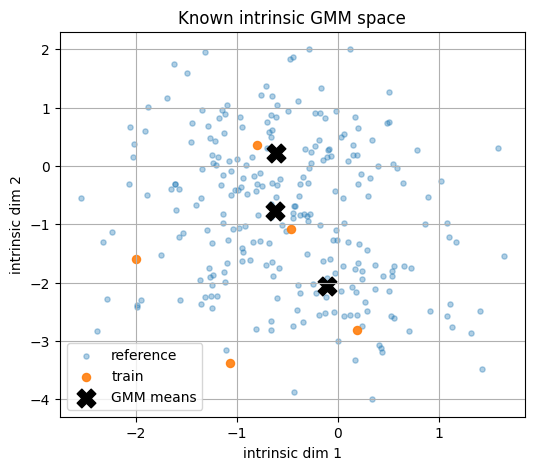

In [4]:
# Purpose: Display the train and reference points in intrinsic space.
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    reference_intrinsic[:, 0],
    reference_intrinsic[:, 1],
    s=14,
    alpha=0.35,
    label="reference",
)
ax.scatter(train_intrinsic[:, 0], train_intrinsic[:, 1], s=34, alpha=0.9, label="train")
ax.scatter(means[:, 0], means[:, 1], s=180, marker="X", c="black", label="GMM means")
ax.set_title("Known intrinsic GMM space")
ax.set_xlabel("intrinsic dim 1")
ax.set_ylabel("intrinsic dim 2")
ax.legend(loc="best")
plt.show()

## 5. Inspect the ambient tensors

This heatmap shows the actual eight-dimensional vectors that the model sees.

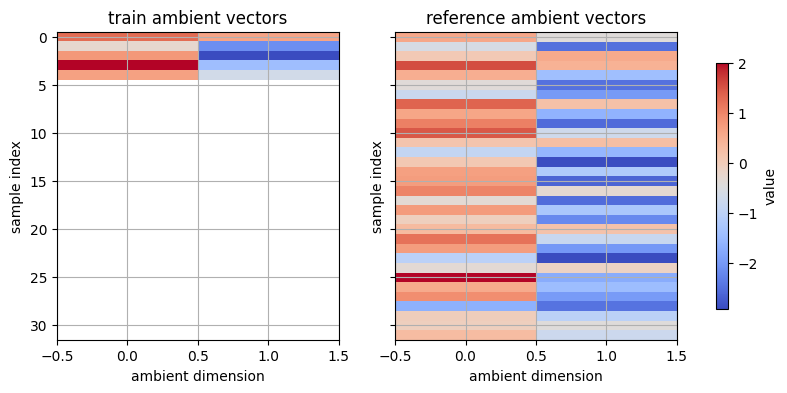

In [5]:
# Purpose: Display the train and reference vectors in ambient space.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, tensor, title in zip(
    axes, [train[:32], reference[:32]], ["train", "reference"]
):
    image = ax.imshow(tensor, aspect="auto", cmap="coolwarm")
    ax.set_title(f"{title} ambient vectors")
    ax.set_xlabel("ambient dimension")
    ax.set_ylabel("sample index")
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label="value")
plt.show()

## 6. Build the model and check one loss value

This checks that config, network construction, path conversion, and loss computation agree.

In [6]:
# Purpose: Build the model and optimizer, then measure the initial loss.
device = torch.device("cpu")

model = GDFM(cfg).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=float(cfg.training.lr),
    weight_decay=float(cfg.training.weight_decay),
)

with torch.no_grad():
    first_loss = model.compute_loss(train[: cfg.training.batch_size].to(device)).item()

n_params = sum(p.numel() for p in model.parameters())
print(f"parameters: {n_params:,}")
print(f"first loss: {first_loss:.6f}")
print(f"prediction/loss: {model.prediction_space}/{model.loss_space}")

parameters: 50,178
first loss: 2.970610
prediction/loss: x/x


## 7. Sample before training

This gives a baseline. The untrained model should not match the GMM well.

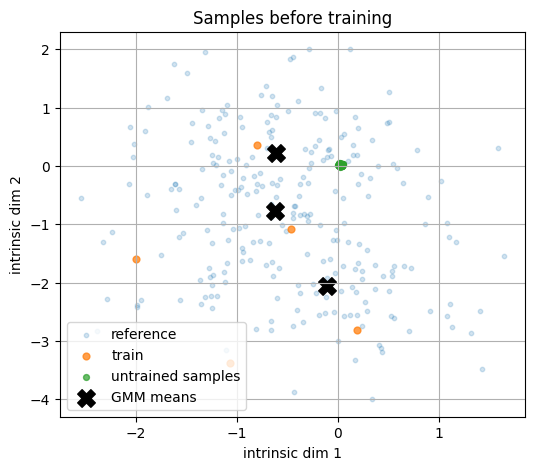

In [7]:
# Purpose: Sample the untrained model from a fixed noise tensor.
generator = torch.Generator().manual_seed(123)
z_eval = torch.randn(
    int(cfg.evaluation.n_samples), int(cfg.data.data_dim), generator=generator
)

with torch.no_grad():
    samples_before = model.sample(
        z_eval,
        n_steps=int(cfg.sampling.n_steps),
        method=str(cfg.sampling.method),
        start_time=float(cfg.sampling.start_time),
        end_time=float(cfg.sampling.end_time),
        use_safe_div=bool(cfg.sampling.use_safe_div),
        safe_div_denominator_floor=float(cfg.sampling.safe_div_denominator_floor),
        output=str(cfg.sampling.output),
        device=device,
    ).cpu()

before_intrinsic = project_to_subspace(samples_before, basis)["intrinsic"]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    reference_intrinsic[:, 0],
    reference_intrinsic[:, 1],
    s=10,
    alpha=0.20,
    label="reference",
)
ax.scatter(
    train_intrinsic[:, 0], train_intrinsic[:, 1], s=24, alpha=0.75, label="train"
)
ax.scatter(
    before_intrinsic[:, 0],
    before_intrinsic[:, 1],
    s=18,
    alpha=0.70,
    label="untrained samples",
)
ax.scatter(means[:, 0], means[:, 1], s=160, marker="X", c="black", label="GMM means")
ax.set_title("Samples before training")
ax.set_xlabel("intrinsic dim 1")
ax.set_ylabel("intrinsic dim 2")
ax.legend(loc="best")
plt.show()

## 8. Train for a short run

This short runtime test checks that gradients flow. It also checks that the loss changes.

step 100 loss 0.871602


step 200 loss 0.846775
step 300 loss 0.523035


step 400 loss 0.619381


step 500 loss 0.528422
step 600 loss 0.552185


step 700 loss 0.544637


step 800 loss 0.552493
step 900 loss 0.613376


... (34 outputs left out)

step 9000 loss 0.358585
step 9100 loss 0.533910
step 9200 loss 0.370157


step 9300 loss 0.459544
step 9400 loss 0.581509
step 9500 loss 0.435110


step 9600 loss 0.481600
step 9700 loss 0.477741
step 9800 loss 0.572874


step 9900 loss 0.497111
step 10000 loss 0.412322


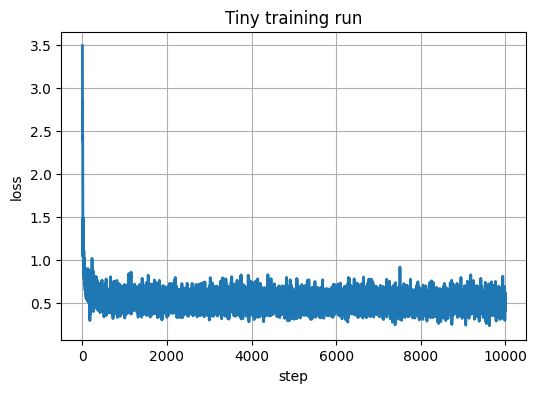

In [8]:
# Purpose: Train the model for the configured optimizer updates.
losses = []
train_device = train.to(device)
batch_size = int(cfg.training.batch_size)
rng = torch.Generator().manual_seed(int(cfg.training.seed))

model.train()
for step in range(1, int(cfg.training.n_training_steps) + 1):
    # Draw a random mini-batch from the fixed training tensor.
    indices = torch.randint(train_device.shape[0], (batch_size,), generator=rng)
    batch = train_device[indices]

    optimizer.zero_grad(set_to_none=True)
    loss = model.compute_loss(batch)
    loss.backward()
    optimizer.step()

    losses.append(float(loss.item()))
    if step % 100 == 0:
        print(f"step {step:3d} loss {losses[-1]:.6f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(losses, lw=2)
ax.set_title("Tiny training run")
ax.set_xlabel("step")
ax.set_ylabel("loss")
plt.show()

## 9. Sample after training

Reuse the same `z_eval`. This controls the initial noise in the before-and-after comparison.

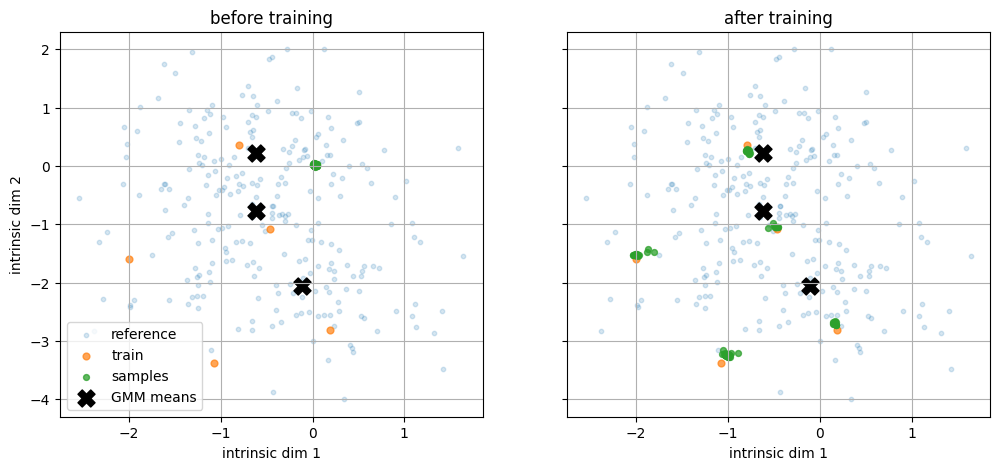

sample mean norm before: 0.03280280902981758
sample mean norm after : 2.430386781692505


In [9]:
# Purpose: Sample the trained model and compare both sample banks.
model.eval()
with torch.no_grad():
    samples_after = model.sample(
        z_eval,
        n_steps=int(cfg.sampling.n_steps),
        method=str(cfg.sampling.method),
        start_time=float(cfg.sampling.start_time),
        end_time=float(cfg.sampling.end_time),
        use_safe_div=bool(cfg.sampling.use_safe_div),
        safe_div_denominator_floor=float(cfg.sampling.safe_div_denominator_floor),
        output=str(cfg.sampling.output),
        device=device,
    ).cpu()

after_intrinsic = project_to_subspace(samples_after, basis)["intrinsic"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, points, title in zip(
    axes, [before_intrinsic, after_intrinsic], ["before training", "after training"]
):
    ax.scatter(
        reference_intrinsic[:, 0],
        reference_intrinsic[:, 1],
        s=10,
        alpha=0.18,
        label="reference",
    )
    ax.scatter(
        train_intrinsic[:, 0], train_intrinsic[:, 1], s=24, alpha=0.70, label="train"
    )
    ax.scatter(points[:, 0], points[:, 1], s=18, alpha=0.75, label="samples")
    ax.scatter(
        means[:, 0], means[:, 1], s=150, marker="X", c="black", label="GMM means"
    )
    ax.set_title(title)
    ax.set_xlabel("intrinsic dim 1")
axes[0].set_ylabel("intrinsic dim 2")
axes[0].legend(loc="best")
plt.show()

print("sample mean norm before:", float(samples_before.norm(dim=1).mean()))
print("sample mean norm after :", float(samples_after.norm(dim=1).mean()))

## 10. Compute memorization and distribution metrics

Nearest-neighbor metrics are data-agnostic. GMM NLL is specific to this synthetic dataset.

In [10]:
# Purpose: Measure memorization and distribution quality after training.
# Compare generated ambient vectors with the training vectors.
ambient_mem = compute_memorization_metrics(
    samples_after, train, rho=float(cfg.evaluation.f_mem_threshold)
)

# Compare generated intrinsic coordinates with the training coordinates.
intrinsic_mem = compute_memorization_metrics(
    after_intrinsic, train_intrinsic, rho=float(cfg.evaluation.f_mem_threshold)
)

# Measure the dataset-specific GMM distribution metrics.
direction_generator = torch.Generator().manual_seed(999)
directions = torch.randn(64, int(cfg.data.intrinsic_dim), generator=direction_generator)
gmm_metrics = gmm_intrinsic_metrics(
    samples_after,
    basis,
    means,
    float(cfg.data.sigma_z),
    float(cfg.data.sigma_eta),
    reference_intrinsic,
    directions,
)

print("ambient memorization")
for key in ["rho", "f_mem", "mean_r", "median_r", "mean_d1", "mean_d2"]:
    print(
        f"  {key:10s}: {ambient_mem[key]:.6f}"
        if isinstance(ambient_mem[key], float)
        else f"  {key:10s}: {ambient_mem[key]}"
    )

print()
print("intrinsic memorization")
for key in ["rho", "f_mem", "mean_r", "median_r", "mean_d1", "mean_d2"]:
    print(
        f"  {key:10s}: {intrinsic_mem[key]:.6f}"
        if isinstance(intrinsic_mem[key], float)
        else f"  {key:10s}: {intrinsic_mem[key]}"
    )

print()
print("GMM distribution metrics")
for key, value in gmm_metrics.items():
    print(f"  {key:24s}: {value:.6f}")

ambient memorization
  rho       : 0.300000
  f_mem     : 1.000000
  mean_r    : 0.084972
  median_r  : 0.086535
  mean_d1   : 0.115187
  mean_d2   : 1.400073

intrinsic memorization
  rho       : 0.300000
  f_mem     : 1.000000
  mean_r    : 0.084974
  median_r  : 0.086535
  mean_d1   : 0.115189
  mean_d2   : 1.400073

GMM distribution metrics
  intrinsic_gmm_nll_mean  : 3.377328
  intrinsic_sliced_w2     : 1.686551


## 11. Look at nearest-neighbor links

This plot connects generated points to their nearest training points in intrinsic space.

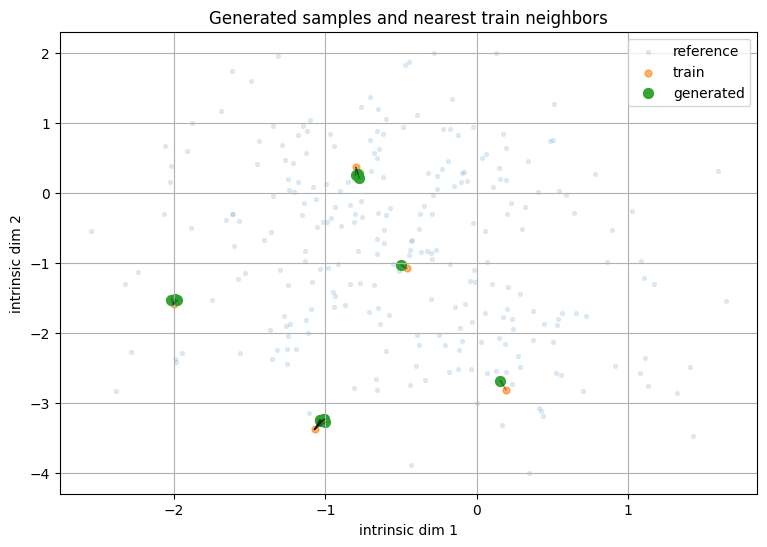

first 10 nearest-neighbor ratios:
tensor([0.0371, 0.1229, 0.0413, 0.1272, 0.1077, 0.1049, 0.0648, 0.0444, 0.1133,
        0.1130])


In [11]:
# Purpose: Connect generated points to their nearest training neighbors.
stats = compute_nn_stats(after_intrinsic, train_intrinsic)
count = 16
sample_points = after_intrinsic[:count]
neighbor_points = train_intrinsic[stats["nn_idx"][:count]]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    reference_intrinsic[:, 0],
    reference_intrinsic[:, 1],
    s=8,
    alpha=0.12,
    label="reference",
)
ax.scatter(
    train_intrinsic[:, 0], train_intrinsic[:, 1], s=24, alpha=0.60, label="train"
)
ax.scatter(
    sample_points[:, 0], sample_points[:, 1], s=50, alpha=0.95, label="generated"
)
for sample_point, neighbor_point in zip(sample_points, neighbor_points):
    ax.plot(
        [sample_point[0], neighbor_point[0]],
        [sample_point[1], neighbor_point[1]],
        color="black",
        alpha=0.35,
        lw=1,
    )
ax.set_title("Generated samples and nearest train neighbors")
ax.set_xlabel("intrinsic dim 1")
ax.set_ylabel("intrinsic dim 2")
ax.legend(loc="best")
plt.show()

print("first 10 nearest-neighbor ratios:")
print(stats["r"][:10])

## 12. Sanity result

The clean path ran if all previous cells completed:

```text
config -> data bundle -> model -> training step -> Heun sampling -> metrics
```

Set `cfg.framework.prediction_space` to `"x"`. Keep `cfg.framework.loss_space = "v"`. Rerun from the model cell to check the `x/v` control.